In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 载入数据
df = sns.load_dataset('titanic')
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
# 查看每一列的缺失值情况
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [3]:
# 1. age 缺失较多，用中位数填充
df['age'] = df['age'].fillna(df['age'].median())

# 2. embarked 缺失很少，直接删掉这两行
df = df.dropna(subset=['embarked'])

# 3. deck 缺失太多了（超过一半），直接删掉这一列
df = df.drop(columns=['deck'])

# 重新检查一下，现在应该没有缺失值了
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

In [4]:
# 把 age 这一列转换成 NumPy 数组
ages = df['age'].values

print(f"乘客平均年龄: {np.mean(ages):.2f} 岁")
print(f"年龄标准差: {np.std(ages):.2f}")

乘客平均年龄: 29.32 岁
年龄标准差: 12.98


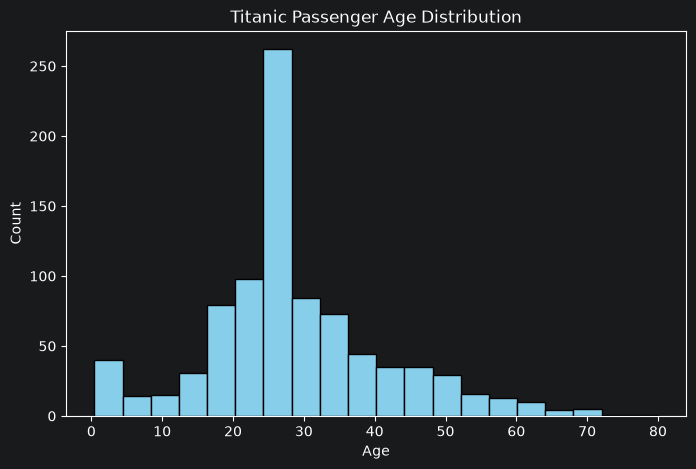

In [5]:
# 画一张年龄分布的直方图
plt.figure(figsize=(8, 5))
plt.hist(df['age'], bins=20, edgecolor='black', color='skyblue')
plt.title('Titanic Passenger Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

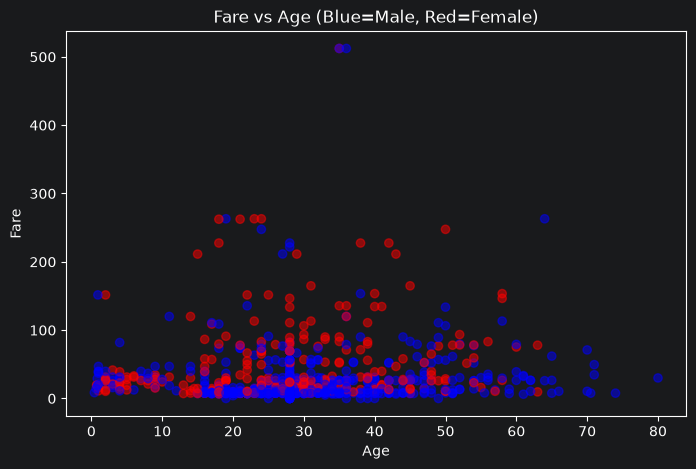

In [6]:
# 画票价与年龄的关系，按性别分颜色
plt.figure(figsize=(8, 5))
# 区分男女颜色
colors = df['sex'].map({'male': 'blue', 'female': 'red'})
plt.scatter(df['age'], df['fare'], c=colors, alpha=0.5)
plt.title('Fare vs Age (Blue=Male, Red=Female)')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.show()